Module 01 Importing Data Sets

In [44]:
import pandas as pd

In [64]:
df=pd.read_csv('D:/export.csv',encoding="utf-8-sig")

In [46]:
df.shape

(294193, 16)

In [47]:
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,5YJ3E1EA5L,Yakima,Yakima,WA,98908.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,266.0,14.0,102765120,POINT (-120.60272 46.59656),PACIFICORP,5.307700e+10
1,5YJ3E1EA9K,Thurston,Olympia,WA,98502.0,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,22.0,326796641,POINT (-122.92018 47.04575),PUGET SOUND ENERGY INC,5.306701e+10
2,5YJSA1H22F,Kitsap,Kingston,WA,98346.0,2015,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,208.0,23.0,166294418,POINT (-122.4977 47.79802),PUGET SOUND ENERGY INC,5.303509e+10
3,KM8K33AG7L,King,Seattle,WA,98107.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258.0,43.0,127090015,POINT (-122.38591 47.67597),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10
4,5YJ3E1EB1K,Yakima,Yakima,WA,98902.0,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,14.0,272512824,POINT (-120.51904 46.59782),PACIFICORP,5.307700e+10


Module 02 Data Wrangling

In [65]:
df_king=df[df['County']=='King'].copy()

In [49]:
df_king.shape

(141971, 16)

In [50]:
df_king.isna().sum()

VIN (1-10)                                           0
County                                               0
City                                                 0
State                                                0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       8
Legislative District                                 0
DOL Vehicle ID                                       0
Vehicle Location                                     0
Electric Utility                                     0
2020 GEOID                                           0
dtype: int64

Module 03 Exploratory Data Analysis

In [84]:
df_king=df_king[df_king["Model Year"]>2020]

In [52]:
yearly=df_king.groupby("Model Year").size().reset_index(name="count")

In [66]:
yearly=yearly[yearly["Model Year"]>=2020].sort_values("Model Year")

In [54]:
print(yearly)

   Model Year  count
0        2021   9698
1        2022  14639
2        2023  30192
3        2024  23463
4        2025  18618
5        2026  17011
6        2027    147


In [55]:
print("Electric Range","\naverage",df_king["Electric Range"].mean())
print("median",df_king["Electric Range"].median())
print("standard deviation",df_king["Electric Range"].std())

Electric Range 
average 5.72457805907173
median 0.0
standard deviation 18.69570667403203


Module 03 - Creating Different Types of Plots in Python

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

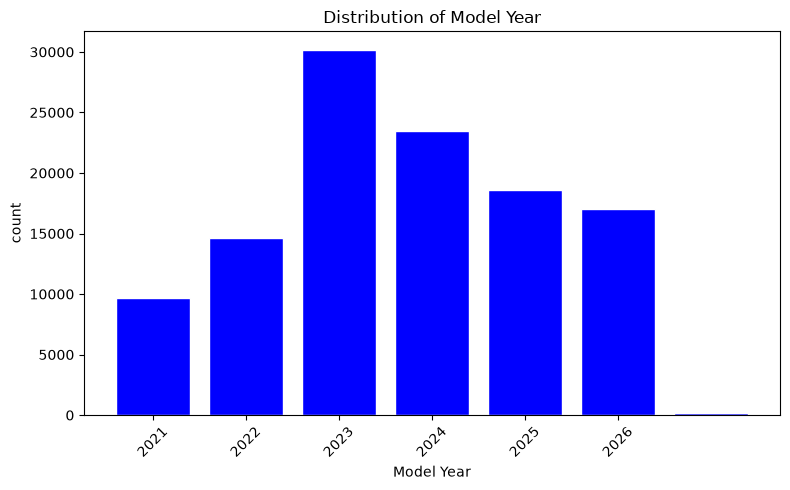

In [57]:
plt.figure(figsize=(8,5))
plt.bar(yearly['Model Year'], yearly['count'],color="blue",edgecolor="white")
plt.xlabel("Model Year")
plt.ylabel("count")
plt.title("Distribution of Model Year")
plt.xticks(range(2021, 2027, 1), rotation=45)
plt.tight_layout()
plt.savefig("model_year.png", dpi=150)
plt.show()

In [58]:
range_data=df_king[df_king['Electric Range']>0]['Electric Range']

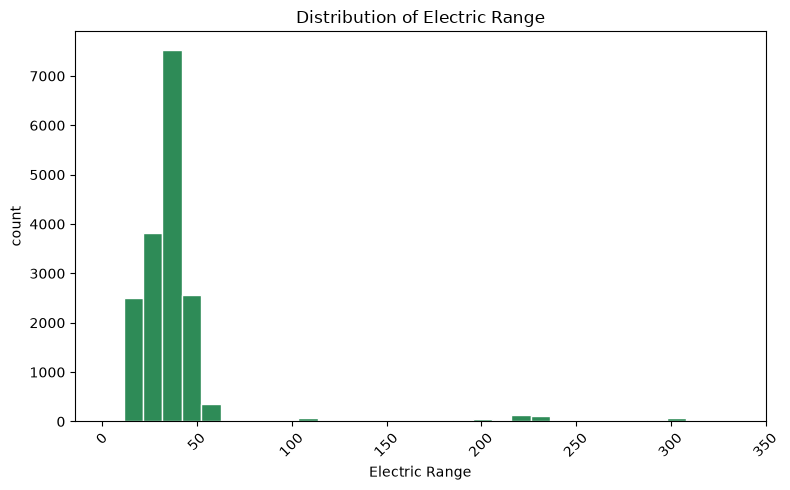

In [59]:
plt.figure(figsize=(8, 5))
plt.hist(range_data, bins=30,color="seagreen", edgecolor="white")
plt.xlabel("Electric Range")
plt.ylabel("count")
plt.title("Distribution of Electric Range")
plt.xticks(range(0, int(range_data.max()) + 50, 50), rotation=45)
plt.tight_layout()
plt.savefig("electric_range.png", dpi=150)
plt.show()

In [60]:
top_makes=df_king["Make"].value_counts().head(10)

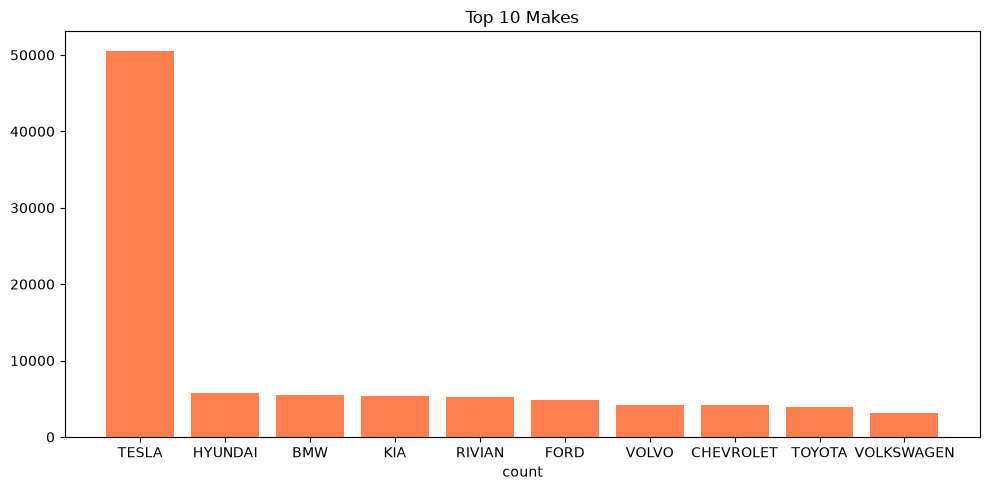

In [61]:
plt.figure(figsize=(10,5))
plt.bar(top_makes.index,top_makes.values,color="coral")
plt.xlabel("count")
plt.title("Top 10 Makes")
plt.tight_layout()
plt.savefig("Top10makes.png", dpi=150)
plt.show()

Model Development

LinearRegression

In [99]:
df_model = df_king[["Model Year", "Electric Range", "Make", "Electric Vehicle Type"]].dropna()
df_model = df_model[df_model["Electric Range"] > 0]
top5 = df_model["Make"].value_counts().head(5).index
df_model["Make"] = df_model["Make"].where(df_model["Make"].isin(top5), "OTHER")
df_model = pd.get_dummies(df_model, columns=["Make", "Electric Vehicle Type"], drop_first=True)

In [100]:
X = df_model.drop("Electric Range", axis=1)
y = df_model[["Electric Range"]]

In [106]:
import sklearn
from sklearn.linear_model import LinearRegression
lm=LinearRegression()
lm.fit(X,y)
print("\n===== LinearRegression =====")
print(lm.intercept_)
print(lm.coef_)
print(f"R²:{lm.score(X,y)}")


===== LinearRegression =====
[-5062.730066]
[[   2.61264084   -9.64136283   -1.46390761   -0.43876029    8.53531198
    -1.91274542 -191.46434289]]
R²:0.8845779235380271


In [113]:
yhat=lm.predict(X)
from sklearn.metrics import r2_score,mean_squared_error
print(r2_score(y,yhat))
mean_squared_error(y, yhat)

0.8845779235380271


126.55099674341733

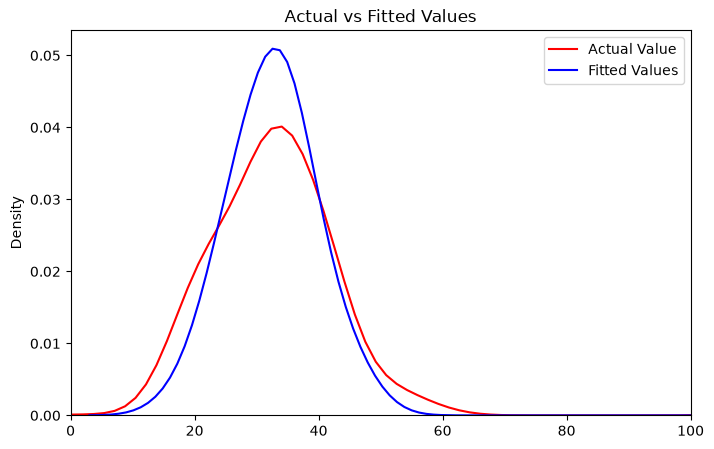

In [120]:
y_flat = np.ravel(y)
yhat_flat = np.ravel(yhat)
plt.figure(figsize=(8, 5))
sns.kdeplot(x=y_flat, color="red", label="Actual Value")
sns.kdeplot(x=yhat_flat, color="blue", label="Fitted Values")
plt.xlim(0, 100)
plt.title("Actual vs Fitted Values")
plt.legend()
plt.savefig("linearregression_plot.png", dpi=150)
plt.show()

PolynomialFeatures

In [126]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
Input=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(include_bias=False)), ('model',LinearRegression())]
pipe=Pipeline(Input)
pipe.fit(X,y)
ypipe=pipe.predict(X)
print(r2_score(y,ypipe))

0.9200474532427927


In [130]:
model = pipe.named_steps["model"] 
poly = pipe.named_steps["polynomial"] 
scaler = pipe.named_steps["scale"]
coefs = model.coef_
intercept = model.intercept_

In [134]:
print(coefs)
print(intercept)

[[ 4.11298592e+00 -4.58865704e-01 -2.03438606e-02 -1.93635587e-02
   5.73201370e-01 -1.32310170e-01 -1.15343246e+00 -3.77032644e-01
  -1.56422992e+00 -9.56888739e-01 -1.30364857e-01 -6.65743832e-01
   3.67447392e-02 -7.77874741e+00 -1.10375459e+00  1.45513711e-01
   3.46648995e-01 -7.77417793e-03  2.36080229e-01  3.39391168e-01
  -6.14414810e-02  2.08886604e-02 -1.63746299e-01  4.81840984e-02
   3.43854154e-01 -1.18272190e-02 -4.15867072e-01  1.05879782e-01
  -1.56154990e+00  1.07002173e+00 -1.77674753e-01  5.98008457e-01
  -2.68210164e-01  4.50878435e-01  6.63552789e+00]]
[33.1336949]


Model Refinement

Ridge

In [135]:
from sklearn.linear_model import Ridge

In [142]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
pipe1 = Pipeline([("polynomial", PolynomialFeatures(degree=2, include_bias=False)),("model", Ridge(alpha=1))])
pipe1.fit(X_train, y_train)
ypre = pipe.predict(X_test)
print(r2_score(y_test, ypre))

0.9271601618662011


Grid Search

In [143]:
from sklearn.model_selection import GridSearchCV
param_grid = {"polynomial__degree": [1, 2, 3],"model__alpha": [0.1, 1, 10, 100]}
grid = GridSearchCV(pipe1, param_grid, cv=5, scoring="r2")
grid.fit(X_train, y_train)
print("best:", grid.best_params_)
print("test R²:", grid.score(X_test, y_test))

D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.2427586774744054e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.246550873530733e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.237499439022391e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.2795900509130787e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\APP

best: {'model__alpha': 0.1, 'polynomial__degree': 3}
test R²: 0.9269777921706424


D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 2.272501239441735e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
D:\APP\conda_data\envs\jupyter_env\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.8047382074953565e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


In [144]:
print(grid.score(X_train, y_train))
print(grid.score(X_test, y_test))

0.9152247003698635
0.9269777921706424


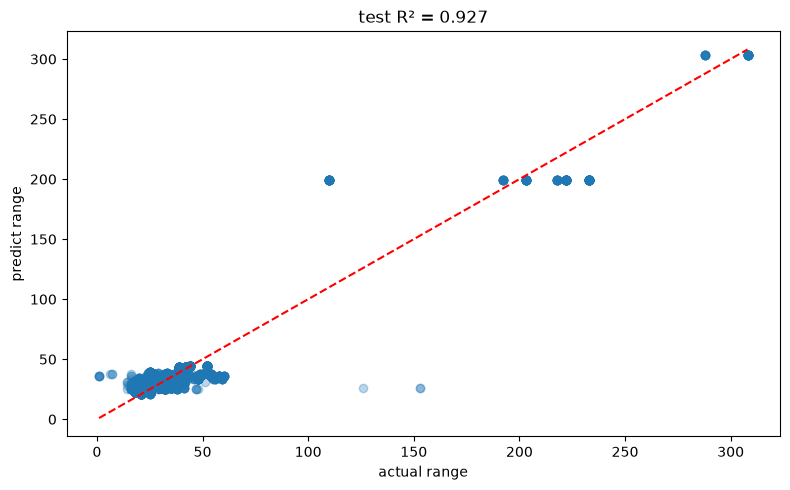

In [146]:
import matplotlib.pyplot as plt
y_pred = grid.predict(X_test)
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("actual range")
plt.ylabel("predict range")
plt.title(f"test R² = {0.927:.3f}")
plt.tight_layout()
plt.savefig("Test R.png", dpi=150)
plt.show()